# fedOPD - algorithm comparison

`06_federated_forecast.ipynb` established one configuration and one null: a two-layer network trained
with FedAvg does not beat repeating last month's value. This notebook asks whether that null survives
changing the things that were held fixed, and it fixes the one confound `06` left open.

**Nothing here touches the test year.** Every number is scored on the validation window that `05`
fixed, exactly as `06` was.

## What is varied, declared before running

One factor at a time from a stated reference configuration. **Not a full grid** - a full cross-product
of 54 runs invites picking the best cell after the fact, which is the failure the project's own rules
forbid. Each axis answers a question that was already open in the worklog:

| Axis | Variants | The open question it answers |
|---|---|---|
| **Anchoring** | train-mean, last-value, delta | Entry 35.3 - is the network losing because it is anchored to a level the data has left? |
| **Architecture** | linear, MLP, GRU | Is the null a property of the model class or of the problem? |
| **FL algorithm** | FedAvg, FedProx, FedAvgM | Do the standard fixes for heterogeneous clients help here? |
| **Features** | demand only, demand + backlog + throughput | Entry 30.3 - seven of eight canonical measures are never shown to the model |

## The confound this notebook fixes

`06` gave FedAvg **three times** the gradient work of the central model, so its
federation-versus-pooling comparison was not a comparison. Here every method gets the **same number of
passes over the same data**: `ROUNDS x LOCAL_EPOCHS` epochs for central and for each local model, and
`ROUNDS` rounds of `LOCAL_EPOCHS` for the federated ones. Budget is stated, not incidental.

## Rules this notebook runs under

- One seed, declared. Every configuration reported, including the ones that lose.
- Metrics chosen before the run: median MASE, within-series R squared, and **precision on the "up"
  call**, which is what the decision layer consumes.
- The reference configuration is fixed in advance and is **not** re-chosen after seeing results.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(0)                                   # one seed, declared

CANON = Path("../data/canonical")
panel = pd.read_parquet(CANON / "rtt_panel.parquet")
index = pd.read_csv(CANON / "series_index.csv", parse_dates=["split_month"])

SPLIT = index.split_month.iloc[0]                      # inherited from 05, never re-chosen here
H = int(index.horizon.iloc[0])
L = 24                                                 # lookback
ROUNDS, LOCAL_EPOCHS = 15, 2                           # the shared budget: 30 epochs of work for everyone
BAND = 0.05                                            # the up/flat/down band, same as 06

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device", device, "| split", SPLIT.strftime("%Y-%m"), "| lookback", L, "-> horizon", H)
print("budget: every method gets", ROUNDS * LOCAL_EPOCHS, "epochs of gradient work over its own data")

device cuda | split 2024-04 | lookback 24 -> horizon 12
budget: every method gets 30 epochs of gradient work over its own data


## 1. The data, in three feature channels

`demand` is the target. `waiting` (backlog) and `completed` (throughput) are the two other measures the
decision layer already reads, and they are the plausible candidates: a long queue may suppress
referrals, a cleared one may release them. They are loaded here as extra channels so the feature axis
can be switched on and off without touching anything else.

Each channel is scaled **per series, from training months only**. A channel scaled on the full window
would leak the evaluation period into training through its mean.

In [2]:
CHANNELS = ["demand", "waiting", "completed"]
keys = list(zip(index.provider_code, index.dept))

raw = {}
for ch in CHANNELS:
    w = panel.pivot(index=["provider_code", "dept"], columns="month", values=ch).loc[keys]
    w.columns = pd.to_datetime(w.columns)
    raw[ch] = w

months = raw["demand"].columns
train_cols = months < SPLIT
score_cols = (months >= SPLIT) & (months < SPLIT + pd.DateOffset(months=H))
assert score_cols.sum() == H, "the scored window is not H months - the test year may be leaking in"

hist = {ch: raw[ch].loc[:, train_cols].to_numpy(dtype=np.float32) for ch in CHANNELS}
future = raw["demand"].loc[:, score_cols].to_numpy(dtype=np.float32)
scale = index.mase_scale.to_numpy()
trusts = index.provider_code.to_numpy()
n_series = len(future)

norm = {ch: hist[ch].mean(axis=1) + 1.0 for ch in CHANNELS}   # per-series, training months only
month_ix = np.array([m.month - 1 for m in months[train_cols]])
eye = np.eye(12, dtype=np.float32)

print(n_series, "series x", hist["demand"].shape[1], "training months x", H, "scored months")
print("channels:", CHANNELS)
print("last training month", months[train_cols][-1].strftime("%Y-%m"),
      "| first scored month", months[score_cols][0].strftime("%Y-%m"))

2085 series x 72 training months x 12 scored months
channels: ['demand', 'waiting', 'completed']
last training month 2024-03 | first scored month 2024-04


## 2. Anchoring - the hypothesis from Entry 35.3

The validation window sits about half a standard deviation above the training mean, because demand
genuinely rose. A network scaled by its series' **training mean** is anchored to a level the data has
since left; `naive` is anchored to the **last observed value** and gets that shift for free. Three
anchorings are therefore tested:

- **`train_mean`** - divide by the training mean. What `06` did.
- **`last_value`** - divide by the mean of the final 3 input months, so the scale follows the series.
- **`delta`** - predict the change from the final input month rather than the level, then add it back.

The prediction, stated before running: if the level-anchoring explanation is right, `last_value` and
`delta` should close most of the gap to `naive`. If they do not, the problem is that month-level
movement at this granularity is genuinely unpredictable.

In [3]:
def build_windows(anchoring, use_extra):
    # returns per-client tensors and the test inputs, under one anchoring and feature choice
    chans = CHANNELS if use_extra else ["demand"]
    clients, Xte = {}, []
    anchors_te = np.zeros(n_series, dtype=np.float32)

    for code in np.unique(trusts):
        rows = np.flatnonzero(trusts == code)
        xs, ys = [], []
        for r in rows:
            series = {ch: hist[ch][r] / norm[ch][r] for ch in chans}     # locally scaled
            d = series["demand"]
            for t in range(len(d) - L - H + 1):
                win = np.concatenate([series[ch][t:t + L] for ch in chans])
                a = d[t + L - 3:t + L].mean() if anchoring != "train_mean" else 1.0
                a = a if a > 1e-6 else 1.0                 # a dead stretch cannot set the scale
                if anchoring == "train_mean":
                    xin, yout = win, d[t + L:t + L + H]
                elif anchoring == "last_value":
                    xin, yout = win / a, d[t + L:t + L + H] / a
                else:                                      # delta: predict change from the last month
                    xin, yout = win, d[t + L:t + L + H] - d[t + L - 1]
                xs.append(np.concatenate([xin, eye[month_ix[t + L - 1]]]))
                ys.append(yout)
        clients[code] = (torch.tensor(np.array(xs)), torch.tensor(np.array(ys)), rows)

    for r in range(n_series):
        series = {ch: hist[ch][r] / norm[ch][r] for ch in chans}
        d = series["demand"]
        win = np.concatenate([series[ch][-L:] for ch in chans])
        a = d[-3:].mean() if anchoring != "train_mean" else 1.0
        a = a if a > 1e-6 else 1.0
        anchors_te[r] = a
        xin = win / a if anchoring == "last_value" else win
        Xte.append(np.concatenate([xin, eye[month_ix[-1]]]))
    return clients, torch.tensor(np.array(Xte)), anchors_te

def to_referrals(scaled, anchoring, anchors):
    # undo the anchoring and the per-series scaler, so every method is scored in the same units
    if anchoring == "delta":
        last = hist["demand"][:, -1] / norm["demand"]
        out = (scaled + last[:, None]) * norm["demand"][:, None]
    elif anchoring == "last_value":
        out = scaled * anchors[:, None] * norm["demand"][:, None]
    else:
        out = scaled * norm["demand"][:, None]
    return np.clip(out, 0, None)

print("windowing defined for 3 anchorings x 2 feature sets")

windowing defined for 3 anchorings x 2 feature sets


## 3. Models and federated algorithms

Three architectures. The **linear** model is included deliberately: if it matches the MLP, the extra
capacity is doing nothing and the null is about the problem rather than the model.

Three server algorithms, all standard responses to clients whose data differs:

- **FedAvg** - plain weighted averaging.
- **FedProx** - each client adds a penalty for drifting from the global weights, which limits damage
  from clients whose local optimum is far from the consensus.
- **FedAvgM** - the server keeps momentum across rounds instead of jumping to each new average.

In [4]:
HIDDEN = 128

class GRUNet(nn.Module):
    # a recurrent model: reads the lag window as a sequence rather than a flat vector
    def __init__(self, n_chan, n_cal):
        super().__init__()
        self.n_chan, self.n_cal = n_chan, n_cal
        self.gru = nn.GRU(n_chan, 64, batch_first=True)
        self.head = nn.Linear(64 + n_cal, H)
    def forward(self, x):
        lags, cal = x[:, :self.n_chan * L], x[:, self.n_chan * L:]
        seq = lags.view(-1, self.n_chan, L).transpose(1, 2)      # (batch, time, channel)
        _, h = self.gru(seq)
        return self.head(torch.cat([h[-1], cal], dim=1))

def make_model(arch, in_dim, n_chan):
    if arch == "linear":
        return nn.Linear(in_dim, H).to(device)
    if arch == "mlp":
        return nn.Sequential(nn.Linear(in_dim, HIDDEN), nn.ReLU(), nn.Dropout(0.1),
                             nn.Linear(HIDDEN, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, H)).to(device)
    return GRUNet(n_chan, in_dim - n_chan * L).to(device)

def get_w(m): return [p.detach().clone() for p in m.parameters()]
def set_w(m, w):
    with torch.no_grad():
        for p, q in zip(m.parameters(), w): p.copy_(q)

def train_local(model, X, Y, epochs, lr=1e-3, prox_mu=0.0, global_w=None):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()
    X, Y = X.to(device), Y.to(device)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 256):
            b = perm[i:i + 256]
            opt.zero_grad()
            loss = loss_fn(model(X[b]), Y[b])
            if prox_mu > 0:                                # FedProx: penalise drift from the server
                for p, g in zip(model.parameters(), global_w):
                    loss = loss + prox_mu / 2 * ((p - g) ** 2).sum()
            loss.backward()
            opt.step()

def predict(model, Xte):
    model.eval()
    with torch.no_grad():
        return model(Xte.to(device)).cpu().numpy()

print("architectures: linear, mlp, gru | algorithms: fedavg, fedprox, fedavgm")

architectures: linear, mlp, gru | algorithms: fedavg, fedprox, fedavgm


In [5]:
def run(arch="mlp", anchoring="train_mean", algo="fedavg", use_extra=False, mode="federated"):
    # one full configuration, trained under the shared budget and scored in referrals
    clients, Xte, anchors = build_windows(anchoring, use_extra)
    n_chan = 3 if use_extra else 1
    in_dim = Xte.shape[1]
    codes = list(clients)
    sizes = np.array([len(clients[c][0]) for c in codes], dtype=float)
    alpha = sizes / sizes.sum()

    if mode == "central":                                  # pooled, same total epochs
        m = make_model(arch, in_dim, n_chan)
        X = torch.cat([clients[c][0] for c in codes]); Y = torch.cat([clients[c][1] for c in codes])
        train_local(m, X, Y, ROUNDS * LOCAL_EPOCHS)
        return to_referrals(predict(m, Xte), anchoring, anchors)

    if mode == "local":                                    # per site, same total epochs each
        out = np.zeros((n_series, H), dtype=np.float32)
        for c in codes:
            X, Y, rows = clients[c]
            m = make_model(arch, in_dim, n_chan)
            train_local(m, X, Y, ROUNDS * LOCAL_EPOCHS)
            out[rows] = predict(m, Xte[rows])
        return to_referrals(out, anchoring, anchors)

    w = get_w(make_model(arch, in_dim, n_chan))            # federated
    velocity = [torch.zeros_like(p) for p in w]
    model = make_model(arch, in_dim, n_chan)
    for _ in range(ROUNDS):
        acc = [torch.zeros_like(p) for p in w]
        for a, c in zip(alpha, codes):
            set_w(model, w)
            train_local(model, clients[c][0], clients[c][1], LOCAL_EPOCHS,
                        prox_mu=0.01 if algo == "fedprox" else 0.0, global_w=w)
            for i, p in enumerate(get_w(model)): acc[i] += a * p   # weighted running sum
        if algo == "fedavgm":                              # server momentum on the update direction
            for i in range(len(w)):
                velocity[i] = 0.9 * velocity[i] + (acc[i] - w[i])
                w[i] = w[i] + velocity[i]
        else:
            w = acc
    set_w(model, w)
    return to_referrals(predict(model, Xte), anchoring, anchors)

print("run() defined - one call is one complete configuration")

run() defined - one call is one complete configuration


## 4. Scoring

Identical to `05` and `06` so every number in the project remains comparable: median MASE on the
denominator `05` computed, within-series R squared against each series' own mean, and precision on the
**up** call against the measured base rate.

In [6]:
ref = hist["demand"][:, -12:].mean(axis=1)
ss_pooled = ((future - future.mean()) ** 2).sum()          # one grand mean over every series-month
ss_within = ((future - future.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
truth_growth = future.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
truth_up = truth_growth > BAND
base_rate = np.nanmean(truth_up) * 100

def score(name, pred):
    err = pred - future
    mae = np.abs(err).mean(axis=1)
    mase = np.where(scale > 0, mae / np.where(scale > 0, scale, 1), np.nan)
    ss_res = (err ** 2).sum(axis=1)
    r2w = np.where(ss_within > 0, 1 - ss_res / np.where(ss_within > 0, ss_within, 1), np.nan)
    g = pred.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
    said = g > BAND
    ok = np.isfinite(g) & np.isfinite(truth_growth)
    prec = np.nanmean(truth_up[ok & said]) * 100 if (ok & said).sum() else np.nan
    return {"config": name, "MASE_median": np.nanmedian(mase),
            "RMSE_median": np.median(np.sqrt((err ** 2).mean(axis=1))),
            "RMSE_pooled": np.sqrt((err ** 2).mean()),
            "R2_pooled": 1 - ss_res.sum() / ss_pooled,
            "R2_within_median": np.nanmedian(r2w),
            "precision_up_pct": prec, "n_said_up": int((ok & said).sum())}

print(f"base rate for the up call: {base_rate:.1f}% of {int(np.isfinite(truth_growth).sum()):,} services")
print("any precision at or below that line is worth nothing")

base rate for the up call: 43.5% of 1,978 services
any precision at or below that line is worth nothing


## 5. The runs

The reference configuration is **MLP, train-mean anchoring, FedAvg, demand only** - what `06` ran -
and each axis is varied from it. `naive` is carried through as the bar.

In [7]:
naive_pred = np.repeat(hist["demand"][:, -1:], H, axis=1)
results = [score("baseline: naive (repeat last value)", naive_pred)]

GRID = [
    ("reference: mlp / train_mean / fedavg / demand",      dict()),
    ("anchoring: last_value",                              dict(anchoring="last_value")),
    ("anchoring: delta",                                   dict(anchoring="delta")),
    ("architecture: linear",                               dict(arch="linear")),
    ("architecture: gru",                                  dict(arch="gru")),
    ("algorithm: fedprox",                                 dict(algo="fedprox")),
    ("algorithm: fedavgm",                                 dict(algo="fedavgm")),
    ("features: + backlog + throughput",                   dict(use_extra=True)),
    ("mode: central (matched budget)",                     dict(mode="central")),
    ("mode: local (matched budget)",                       dict(mode="local")),
]

for name, kw in GRID:
    results.append(score(name, run(**kw)))
    r = results[-1]
    print(f"{name:46s} MASE {r['MASE_median']:.3f}  prec_up {r['precision_up_pct']:5.1f}%  "
          f"n_up {r['n_said_up']:4d}")

table = pd.DataFrame(results).set_index("config")
print()
print(table.round(3).to_string())

reference: mlp / train_mean / fedavg / demand  MASE 0.507  prec_up  70.0%  n_up  387


anchoring: last_value                          MASE 0.503  prec_up  69.3%  n_up  482


anchoring: delta                               MASE 0.612  prec_up  71.4%  n_up  248


architecture: linear                           MASE 0.611  prec_up  48.8%  n_up  557


architecture: gru                              MASE 0.676  prec_up  53.8%  n_up  480


algorithm: fedprox                             MASE 0.507  prec_up  66.7%  n_up  402


algorithm: fedavgm                             MASE 2.159  prec_up  46.0%  n_up 1970


features: + backlog + throughput               MASE 0.533  prec_up  57.9%  n_up  916


mode: central (matched budget)                 MASE 0.603  prec_up  66.4%  n_up  330


mode: local (matched budget)                   MASE 0.556  prec_up  62.4%  n_up  370

                                               MASE_median  RMSE_median  RMSE_pooled  R2_pooled  R2_within_median  precision_up_pct  n_said_up
config                                                                                                                                        
baseline: naive (repeat last value)                  0.510    72.778000   186.731003      0.968            -0.667            68.670        549
reference: mlp / train_mean / fedavg / demand        0.507    69.658997   178.921997      0.970            -0.488            70.026        387
anchoring: last_value                                0.503    70.330002   183.072006      0.969            -0.500            69.295        482
anchoring: delta                                     0.612    85.011002   212.886002      0.958            -1.138            71.371        248
architecture: linear                                 0.6

In [8]:
best_point = table.MASE_median.idxmin()
best_dec = table.precision_up_pct.idxmax()
print("best on point accuracy :", best_point, f"({table.MASE_median.min():.3f})")
print("best on the up call    :", best_dec, f"({table.precision_up_pct.max():.1f}% vs {base_rate:.1f}% base)")
print()

bar = table.loc["baseline: naive (repeat last value)", "MASE_median"]
beat = table[table.MASE_median < bar]
if len(beat) <= 1:
    print("NO CONFIGURATION BEATS THE NAIVE BASELINE ON POINT ACCURACY.")
    print("The Entry 35.3 level-anchoring hypothesis is then not the explanation, and the null in")
    print("F-44 is a property of the problem rather than of the configuration 06 happened to pick.")
else:
    print("Configurations beating naive on median MASE:")
    print(beat.MASE_median.sort_values().round(3).to_string())

table.to_csv(CANON / "algorithm_comparison.csv")
print()
print("written: algorithm_comparison.csv")

best on point accuracy : anchoring: last_value (0.503)
best on the up call    : anchoring: delta (71.4% vs 43.5% base)

Configurations beating naive on median MASE:
config
anchoring: last_value                            0.503
reference: mlp / train_mean / fedavg / demand    0.507
algorithm: fedprox                               0.507

written: algorithm_comparison.csv


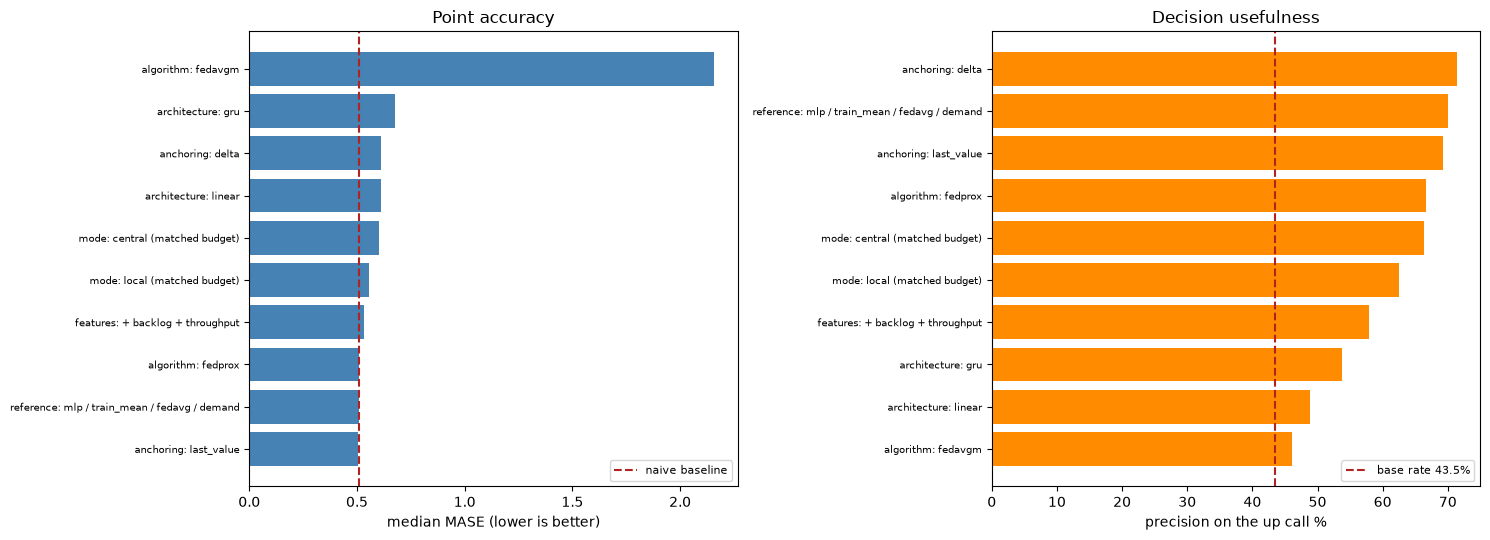

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
t = table.drop(index="baseline: naive (repeat last value)")

order = t.MASE_median.sort_values()
ax[0].barh(range(len(order)), order.to_numpy(), color="steelblue")
ax[0].axvline(bar, color="firebrick", ls="--", label="naive baseline")
ax[0].set_yticks(range(len(order))); ax[0].set_yticklabels(order.index, fontsize=7)
ax[0].set_xlabel("median MASE (lower is better)"); ax[0].legend(fontsize=8)
ax[0].set_title("Point accuracy")

order2 = t.precision_up_pct.sort_values()
ax[1].barh(range(len(order2)), order2.to_numpy(), color="darkorange")
ax[1].axvline(base_rate, color="firebrick", ls="--", label=f"base rate {base_rate:.1f}%")
ax[1].set_yticks(range(len(order2))); ax[1].set_yticklabels(order2.index, fontsize=7)
ax[1].set_xlabel("precision on the up call %"); ax[1].legend(fontsize=8)
ax[1].set_title("Decision usefulness")
plt.tight_layout()

## What this notebook does and does not settle

**Settles the budget confound.** Every method above receives the same number of passes over the same
data, so `central` and `local` are finally comparable with the federated runs. Whatever ordering
appears here is not a training-budget artefact.

**Does not tune anything.** Learning rate, hidden width, round count and the proximal coefficient are
fixed at ordinary defaults and are the same for every configuration. A sweep over them would very
likely move some numbers, and would also be the point at which this stops being a comparison and starts
being a search for a flattering cell.

**One seed.** Differences of a few thousandths in MASE between neighbouring configurations should be
read as noise, not as ordering.

**The test year is untouched.** Everything here is validation.